# Comparación de modelos preentrenados de Hugging Face para análisis de sentimientos

**Aplicación propuesta:** análisis de sentimientos como apoyo a la revisión y priorización de reclamaciones.

## Propósito
Comparar tres modelos preentrenados de Hugging Face que clasifican textos en **negative**, **neutral** y **positive**. Se evaluarán con el mismo conjunto de prueba mediante accuracy, precision, recall, F1-score macro y latencia de inferencia.

**Importante sobre el alcance:** el dataset seleccionado contiene comentarios de usuarios de aerolíneas, no reclamaciones bancarias. Por ello, los resultados evalúan la clasificación de sentimientos en ese dominio. La posible aplicación a reclamaciones bancarias se plantea como una línea de trabajo futura que requiere validación ya que por el momento no se cuenta con datos bancarios reales etiquetados.

## Modelos candidatos
1. `cardiffnlp/twitter-roberta-base-sentiment`
2. `finiteautomata/bertweet-base-sentiment-analysis`
3. `lxyuan/distilbert-base-multilingual-cased-sentiments-student`

Se verificará la configuración de etiquetas de cada modelo antes de comparar. Si un modelo no produce las tres clases esperadas, debe revisarse su configuración y no deben interpretarse sus resultados como comparables hasta resolverlo.

## Reproducibilidad
- Semilla fija para la partición.
- Mismo conjunto de prueba para los tres modelos.
- Métricas macro para dar el mismo peso a cada clase.
- Registro del dispositivo, versiones de librerías y latencia.
- Los resultados se generan al ejecutar el notebook; no se incluyen métricas inventadas.

## 2. Instalar dependencias

In [1]:
%pip -q install "pandas==2.2.3" "transformers<5" accelerate scikit-learn matplotlib seaborn huggingface_hub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 70.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Configurar entorno y comprobar GPU

In [2]:
import os
import random
import time
import platform
import warnings
import numpy as np
import pandas as pd
import torch
import transformers
import sklearn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 0 if torch.cuda.is_available() else -1
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Python:", platform.python_version())
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("Dispositivo:", DEVICE_NAME)
print("CUDA disponible:", torch.cuda.is_available())

Python: 3.13.15
Pandas: 2.2.3
Scikit-learn: 1.6.1
Transformers: 4.57.6
PyTorch: 2.11.0+cu130
Dispositivo: Tesla T4
CUDA disponible: True


## 3. Autenticación opcional en Hugging Face Hub

In [3]:
import os
from huggingface_hub import login

hf_token = None
try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN")
except Exception:
    hf_token = os.environ.get("HF_TOKEN")

if hf_token:
    login(token=hf_token, add_to_git_credential=False)
    print("Autenticación configurada.")
else:
    print("No se encontró HF_TOKEN. Se intentará descargar los modelos públicos sin autenticación.")

No se encontró HF_TOKEN. Se intentará descargar los modelos públicos sin autenticación.


## 4. Cargar el dataset

El dataset seleccionado contiene una columna de texto (`text`) y la etiqueta (`airline_sentiment`). Se eliminan textos o etiquetas vacías y se conservan únicamente las tres clases objetivo.

In [4]:
from pathlib import Path

DATA_PATH = "/content/Tweets.csv"

if not Path(DATA_PATH).exists():
    try:
        from google.colab import files
        print("Selecciona el archivo Tweets.csv (no el ZIP).")
        uploaded = files.upload()
        csv_candidates = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_candidates:
            raise FileNotFoundError("No se cargó un archivo CSV.")
        DATA_PATH = csv_candidates[0]
    except ImportError:
        raise FileNotFoundError(
            f"No se encontró {DATA_PATH}. Coloca Tweets.csv en esa ruta o cambia DATA_PATH."
        )

df = pd.read_csv(DATA_PATH, encoding="latin-1")
df.columns = df.columns.str.strip()

required_cols = {"text", "airline_sentiment"}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"Faltan columnas requeridas: {missing_cols}. Columnas disponibles: {df.columns.tolist()}")

df = df[["text", "airline_sentiment"]].copy()
df["text"] = df["text"].astype("string").str.strip()
df["airline_sentiment"] = df["airline_sentiment"].astype("string").str.strip().str.lower()
df = df.dropna(subset=["text", "airline_sentiment"])
df = df[df["text"].str.len() > 0]
df = df[df["airline_sentiment"].isin(["negative", "neutral", "positive"])]
df = df.drop_duplicates(subset=["text", "airline_sentiment"]).reset_index(drop=True)

print("Dimensiones tras limpieza:", df.shape)
print("\nDistribución de clases:")
display(df["airline_sentiment"].value_counts().rename_axis("sentimiento").to_frame("registros"))
display(df.head())

Selecciona el archivo Tweets.csv (no el ZIP).


Saving Tweets.csv to Tweets.csv
Dimensiones tras limpieza: (14452, 2)

Distribución de clases:


,registros
sentimiento,
negative,9087
neutral,3067
positive,2298


,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


## 5. Revisar balance de clases

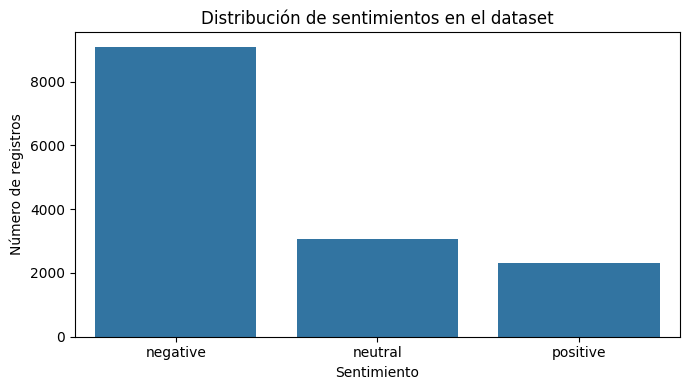

Proporción por clase:


,porcentaje
airline_sentiment,
negative,62.88
neutral,21.22
positive,15.9


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="airline_sentiment", order=["negative", "neutral", "positive"])
ax.set_title("Distribución de sentimientos en el dataset")
ax.set_xlabel("Sentimiento")
ax.set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

print("Proporción por clase:")
display((df["airline_sentiment"].value_counts(normalize=True)
         .reindex(["negative", "neutral", "positive"]) * 100).round(2).rename("porcentaje").to_frame())

## 6. Separar entrenamiento y prueba

Los modelos preentrenados de esta actividad se evalúan sin ajuste fino (inferencia directa). La partición estratificada crea un conjunto de prueba común para todos los modelos. El conjunto de entrenamiento se conserva para documentar el diseño y, si se decide realizar fine-tuning en una extensión futura, deberá usarse sin tocar el test.

In [6]:
from sklearn.model_selection import train_test_split

LABELS = ["negative", "neutral", "positive"]
X = df["text"].astype(str)
y = df["airline_sentiment"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print(f"Total: {len(df):,}")
print(f"Entrenamiento (80%): {len(X_train):,}")
print(f"Prueba (20%): {len(X_test):,}")
print("\nDistribución del conjunto de prueba:")
display(y_test.value_counts(normalize=True).reindex(LABELS).mul(100).round(2).rename("porcentaje").to_frame())

Total: 14,452
Entrenamiento (80%): 11,561
Prueba (20%): 2,891

Distribución del conjunto de prueba:


,porcentaje
airline_sentiment,
negative,62.88
neutral,21.20
positive,15.91


## 7. Cargar modelos de Hugging Face

Se utilizará `pipeline("text-classification")`. Se configura truncamiento para textos extensos y un tamaño de lote moderado para controlar la memoria. Si la GPU se queda sin memoria, reduce `BATCH_SIZE` a 8 o 4.

**Nota:** las etiquetas internas de los modelos pueden aparecer como `LABEL_0`, `LABEL_1`, etc. La función de normalización de la siguiente celda utiliza la configuración `id2label` del modelo y reglas explícitas.

In [7]:
from transformers import pipeline, AutoConfig

MODEL_IDS = {
    "Twitter-RoBERTa": "cardiffnlp/twitter-roberta-base-sentiment",
    "BERTweet": "finiteautomata/bertweet-base-sentiment-analysis",
    "DistilBERT multilingüe": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
}

BATCH_SIZE = 16 if torch.cuda.is_available() else 8
MAX_LENGTH = 128

classifiers = {}
model_configs = {}

for display_name, model_id in MODEL_IDS.items():
    print(f"\nCargando {display_name}: {model_id}")
    config = AutoConfig.from_pretrained(model_id)
    model_configs[display_name] = config
    print("id2label:", config.id2label)
    classifiers[display_name] = pipeline(
        task="text-classification",
        model=model_id,
        tokenizer=model_id,
        device=DEVICE,
    )
    print("Modelo cargado.")


Cargando Twitter-RoBERTa: cardiffnlp/twitter-roberta-base-sentiment


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

id2label: {0: 'LABEL_0', 1: 'LABEL_1', 2: 'LABEL_2'}


pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Device set to use cuda:0


Modelo cargado.


## 8. Normalizar las etiquetas de salida

Los modelos deben entregar una de las tres clases. La función reconoce etiquetas habituales como `LABEL_0` mediante el `id2label` configurado por el modelo, y etiquetas textuales como `positive`, `neutral` y `negative`. Se muestra el mapeo detectado para inspección.

Si aparece una etiqueta desconocida, la función genera un error en lugar de asignar una clase arbitrariamente.

In [8]:
def normalize_sentiment(raw_label, config, model_name):
    label = str(raw_label).strip().lower()

    def from_text(value):
        value = str(value).strip().lower()
        if "negative" in value or value in {"neg", "negativo"}:
            return "negative"
        if "neutral" in value or value in {"neu", "neutro"}:
            return "neutral"
        if "positive" in value or value in {"pos", "positivo"}:
            return "positive"
        return None

    direct = from_text(label)
    if direct:
        return direct

    # Resolver etiquetas genéricas LABEL_n usando la configuración.
    if label.startswith("label_"):
        try:
            idx = int(label.split("_")[-1])
            configured = str(config.id2label[idx]).strip().lower()
            mapped = from_text(configured)
            if mapped:
                return mapped

            # Fallback explícito solo si el repositorio usa etiquetas genéricas.
            # Orden habitual de CardiffNLP/BERTweet: negativo, neutral, positivo.
            if model_name in {"Twitter-RoBERTa", "BERTweet"}:
                generic_order = {0: "negative", 1: "neutral", 2: "positive"}
            # El modelo lxyuan usa el orden positivo, neutral, negativo.
            elif model_name == "DistilBERT multilingüe":
                generic_order = {0: "positive", 1: "neutral", 2: "negative"}
            else:
                generic_order = {}

            if idx in generic_order:
                return generic_order[idx]
        except (ValueError, KeyError, IndexError):
            pass

    raise ValueError(
        f"No se pudo mapear la etiqueta '{raw_label}' para {model_name}. "
        f"Revisa id2label del modelo: {config.id2label}"
    )

for name, config in model_configs.items():
    mapped = {}
    for idx, raw in config.id2label.items():
        try:
            mapped[str(raw)] = normalize_sentiment(str(raw), config, name)
        except ValueError:
            mapped[str(raw)] = "REVISAR"
    print(name, "->", mapped)

Twitter-RoBERTa -> {'LABEL_0': 'negative', 'LABEL_1': 'neutral', 'LABEL_2': 'positive'}
BERTweet -> {'NEG': 'negative', 'NEU': 'neutral', 'POS': 'positive'}
DistilBERT multilingüe -> {'positive': 'positive', 'neutral': 'neutral', 'negative': 'negative'}


## 9. Evaluar los tres modelos

Se evalúa exactamente el mismo `X_test`. Se registran:
- Accuracy.
- Precision, recall y F1-score macro.
- Latencia total y latencia media por texto.
- Throughput (textos por segundo).

La latencia se mide durante la inferencia por lotes en el hardware actual; por ello, solo es comparable entre modelos si se mantiene el mismo entorno, tamaño de lote y conjunto de prueba.

In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

results = []
predictions_by_model = {}
reports_by_model = {}
confusion_by_model = {}

texts_test = X_test.tolist()
y_true = y_test.tolist()

for display_name, clf in classifiers.items():
    print(f"\nEvaluando: {display_name}")
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    outputs = clf(
        texts_test,
        batch_size=BATCH_SIZE,
        truncation=True,
        max_length=MAX_LENGTH
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    y_pred = [normalize_sentiment(out["label"], model_configs[display_name], display_name) for out in outputs]
    predictions_by_model[display_name] = y_pred

    accuracy = accuracy_score(y_true, y_pred)
    precision_macro = precision_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
    recall_macro = recall_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
    f1_macro = f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)

    results.append({
        "modelo": display_name,
        "model_id": MODEL_IDS[display_name],
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "latencia_total_segundos": elapsed,
        "latencia_media_ms_texto": (elapsed / len(texts_test)) * 1000,
        "textos_por_segundo": len(texts_test) / elapsed if elapsed > 0 else np.nan,
        "n_test": len(texts_test),
        "dispositivo": DEVICE_NAME,
        "batch_size": BATCH_SIZE,
        "max_length": MAX_LENGTH,
    })

    reports_by_model[display_name] = classification_report(
        y_true, y_pred, labels=LABELS, output_dict=True, zero_division=0
    )
    confusion_by_model[display_name] = confusion_matrix(y_true, y_pred, labels=LABELS)

    print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))
    print(f"Latencia total: {elapsed:.2f} s | Media: {elapsed/len(texts_test)*1000:.2f} ms/texto")


Evaluando: Twitter-RoBERTa
              precision    recall  f1-score   support

    negative       0.94      0.71      0.81      1818
     neutral       0.49      0.71      0.58       613
    positive       0.66      0.89      0.76       460

    accuracy                           0.74      2891
   macro avg       0.70      0.77      0.72      2891
weighted avg       0.80      0.74      0.75      2891

Latencia total: 10.84 s | Media: 3.75 ms/texto

Evaluando: BERTweet
              precision    recall  f1-score   support

    negative       0.93      0.80      0.86      1818
     neutral       0.56      0.67      0.61       613
    positive       0.67      0.88      0.76       460

    accuracy                           0.78      2891
   macro avg       0.72      0.78      0.74      2891
weighted avg       0.81      0.78      0.79      2891

Latencia total: 7.77 s | Media: 2.69 ms/texto

Evaluando: DistilBERT multilingüe
              precision    recall  f1-score   support

    ne

## 9.1 Evaluación adicional con conjunto de prueba balanceado

El conjunto original se conserva como evaluación principal porque refleja la distribución observada de las clases. Como análisis complementario, se crea una muestra balanceada a partir del conjunto de prueba: se selecciona al azar el mismo número de ejemplos por clase (el tamaño de la clase minoritaria). No se reentrenan los modelos; se reutilizan las predicciones ya generadas y se calculan las métricas sobre las mismas filas para todos los modelos.

**Importante:** este resultado permite comparar el desempeño con igual representación de las clases, pero no sustituye la evaluación original ni representa necesariamente la distribución real de futuros mensajes.

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Índices del conjunto de prueba, manteniendo el índice original de X_test/y_test.
test_frame = pd.DataFrame({
    "text": X_test.to_numpy(),
    "sentimiento_real": y_test.to_numpy(),
}, index=np.arange(len(y_test)))

min_class_n = int(test_frame["sentimiento_real"].value_counts().min())
balanced_parts = [
    test_frame[test_frame["sentimiento_real"] == label].sample(
        n=min_class_n, random_state=SEED
    )
    for label in LABELS
]
balanced_test = pd.concat(balanced_parts).sample(frac=1, random_state=SEED)
balanced_idx = balanced_test.index.to_numpy()
y_balanced = balanced_test["sentimiento_real"].tolist()

print("Tamaño original del test:", len(test_frame))
print("Tamaño del test balanceado:", len(balanced_test))
print("Distribución balanceada:")
display(balanced_test["sentimiento_real"].value_counts().reindex(LABELS).rename("n").to_frame())

balanced_results = []
for model_name, all_preds in predictions_by_model.items():
    preds_balanced = [all_preds[i] for i in balanced_idx]
    balanced_results.append({
        "modelo": model_name,
        "n_test_balanceado": len(y_balanced),
        "accuracy": accuracy_score(y_balanced, preds_balanced),
        "precision_macro": precision_score(y_balanced, preds_balanced, labels=LABELS, average="macro", zero_division=0),
        "recall_macro": recall_score(y_balanced, preds_balanced, labels=LABELS, average="macro", zero_division=0),
        "f1_macro": f1_score(y_balanced, preds_balanced, labels=LABELS, average="macro", zero_division=0),
    })
    print(f"\nReporte por clase — {model_name} (test balanceado)")
    print(classification_report(y_balanced, preds_balanced, labels=LABELS, zero_division=0))

balanced_results_df = pd.DataFrame(balanced_results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(balanced_results_df.style.format({
    "accuracy": "{:.4f}", "precision_macro": "{:.4f}",
    "recall_macro": "{:.4f}", "f1_macro": "{:.4f}"
}))

Path("results").mkdir(exist_ok=True)
balanced_results_df.to_csv("results/comparacion_modelos_test_balanceado.csv", index=False, encoding="utf-8-sig")
print("Guardado: results/comparacion_modelos_test_balanceado.csv")

Tamaño original del test: 2891
Tamaño del test balanceado: 1380
Distribución balanceada:


,n
sentimiento_real,
negative,460
neutral,460
positive,460



Reporte por clase — Twitter-RoBERTa (test balanceado)
              precision    recall  f1-score   support

    negative       0.85      0.72      0.78       460
     neutral       0.68      0.70      0.69       460
    positive       0.79      0.89      0.84       460

    accuracy                           0.77      1380
   macro avg       0.77      0.77      0.77      1380
weighted avg       0.77      0.77      0.77      1380


Reporte por clase — BERTweet (test balanceado)
              precision    recall  f1-score   support

    negative       0.82      0.80      0.81       460
     neutral       0.72      0.66      0.69       460
    positive       0.79      0.88      0.83       460

    accuracy                           0.78      1380
   macro avg       0.78      0.78      0.78      1380
weighted avg       0.78      0.78      0.78      1380


Reporte por clase — DistilBERT multilingüe (test balanceado)
              precision    recall  f1-score   support

    negative      

,modelo,n_test_balanceado,accuracy,precision_macro,recall_macro,f1_macro
0,BERTweet,1380,0.7775,0.7758,0.7775,0.7752
1,Twitter-RoBERTa,1380,0.7688,0.7727,0.7688,0.7680
2,DistilBERT multilingüe,1380,0.5254,0.4611,0.5254,0.4477


Guardado: results/comparacion_modelos_test_balanceado.csv


## 10. Tabla comparativa de resultados (conjunto original)

,modelo,model_id,accuracy,precision_macro,recall_macro,f1_macro,latencia_total_segundos,latencia_media_ms_texto,textos_por_segundo,n_test,dispositivo,batch_size,max_length
0,BERTweet,finiteautomata/bertweet-base-sentiment-analysis,0.7838,0.7213,0.7821,0.7437,7.77,2.69,371.86,2891,Tesla T4,16,128
1,Twitter-RoBERTa,cardiffnlp/twitter-roberta-base-sentiment,0.7420,0.6977,0.7731,0.7172,10.84,3.75,266.58,2891,Tesla T4,16,128
2,DistilBERT multilingüe,lxyuan/distilbert-base-multilingual-cased-sentiments-student,0.5479,0.4248,0.5271,0.4176,4.29,1.48,674.18,2891,Tesla T4,16,128


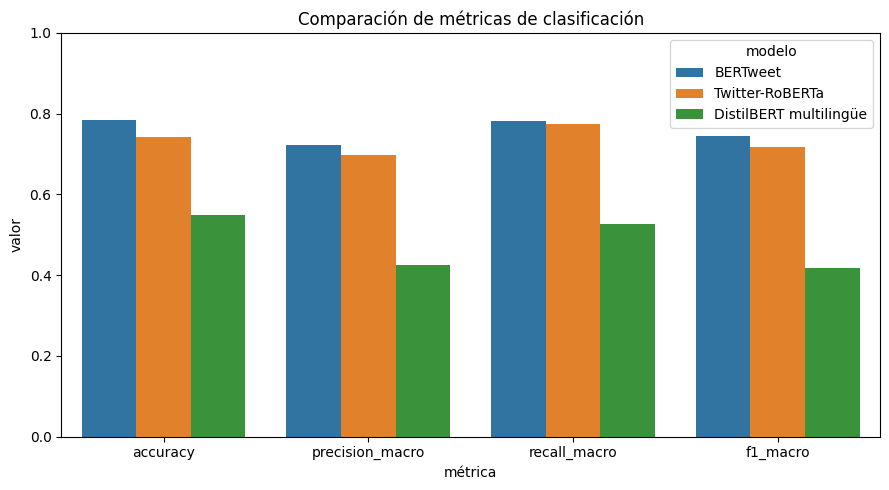

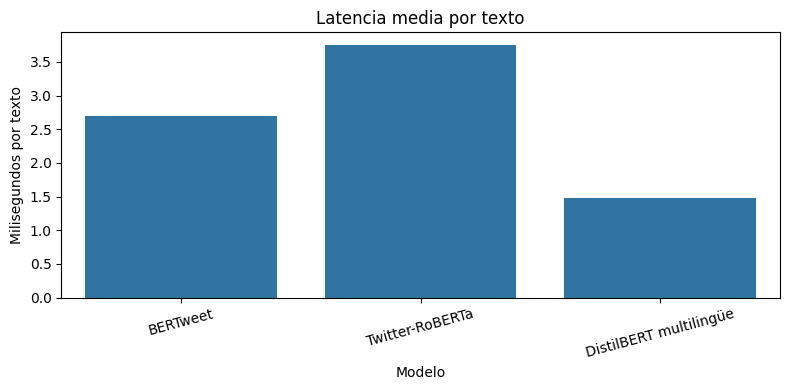

In [11]:
results_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "accuracy": "{:.4f}",
    "precision_macro": "{:.4f}",
    "recall_macro": "{:.4f}",
    "f1_macro": "{:.4f}",
    "latencia_total_segundos": "{:.2f}",
    "latencia_media_ms_texto": "{:.2f}",
    "textos_por_segundo": "{:.2f}",
}))

plt.figure(figsize=(9, 5))
plot_df = results_df.melt(
    id_vars="modelo",
    value_vars=["accuracy", "precision_macro", "recall_macro", "f1_macro"],
    var_name="métrica",
    value_name="valor"
)
sns.barplot(data=plot_df, x="métrica", y="valor", hue="modelo")
plt.ylim(0, 1)
plt.title("Comparación de métricas de clasificación")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="modelo", y="latencia_media_ms_texto")
plt.title("Latencia media por texto")
plt.ylabel("Milisegundos por texto")
plt.xlabel("Modelo")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 11. Matrices de confusión

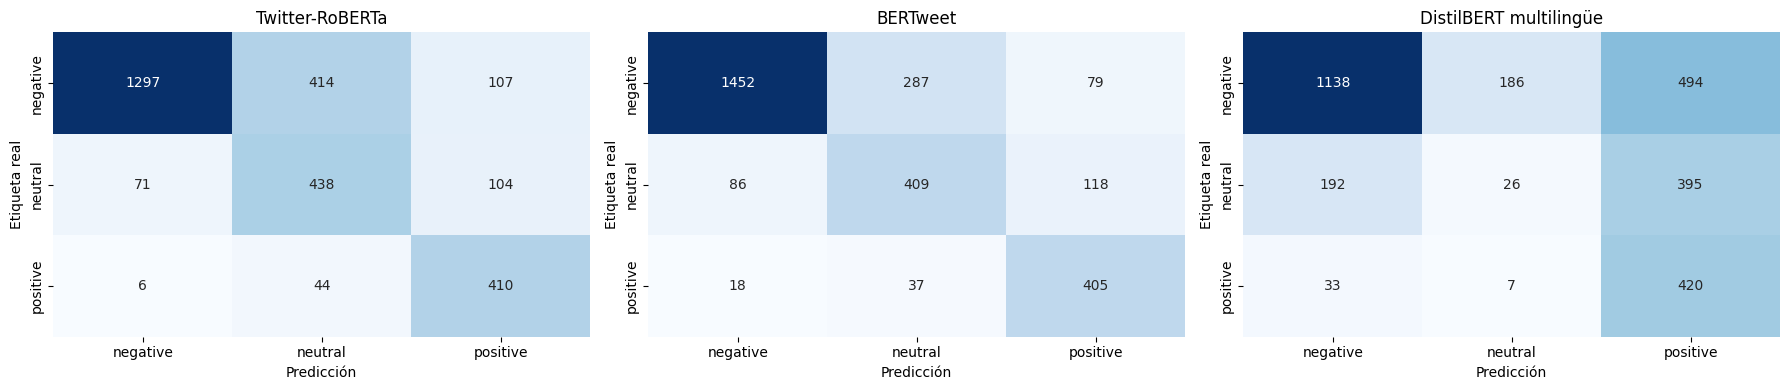

In [12]:
fig, axes = plt.subplots(1, len(confusion_by_model), figsize=(6 * len(confusion_by_model), 4))
if len(confusion_by_model) == 1:
    axes = [axes]

for ax, (name, cm) in zip(axes, confusion_by_model.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=LABELS, yticklabels=LABELS
    )
    ax.set_title(name)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

plt.tight_layout()
plt.show()

## 12. Guardar resultados reproducibles

Se guardan las métricas, predicciones y reportes por clase para integrarlos al reporte Word y al repositorio GitHub. Las predicciones no deben contener datos personales; en este dataset se utiliza el texto público del conjunto seleccionado.

In [13]:
from pathlib import Path
import json

OUT_DIR = Path("results")
OUT_DIR.mkdir(exist_ok=True)

results_df.to_csv(OUT_DIR / "comparacion_modelos.csv", index=False, encoding="utf-8-sig")

pred_df = pd.DataFrame({
    "text": texts_test,
    "sentimiento_real": y_true,
})
for model_name, preds in predictions_by_model.items():
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("í", "i")
    )
    pred_df[f"pred_{safe_name}"] = preds

pred_df.to_csv(OUT_DIR / "predicciones_test.csv", index=False, encoding="utf-8-sig")

for model_name, report in reports_by_model.items():
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_").replace("í", "i")
    with open(OUT_DIR / f"reporte_{safe_name}.json", "w", encoding="utf-8") as f:
        json.dump(report, f, ensure_ascii=False, indent=2)

print("Archivos generados:")
for p in sorted(OUT_DIR.iterdir()):
    print("-", p)

Archivos generados:
- results/comparacion_modelos.csv
- results/comparacion_modelos_test_balanceado.csv
- results/predicciones_test.csv
- results/reporte_bertweet.json
- results/reporte_distilbert_multilingüe.json
- results/reporte_twitter_roberta.json


## 13. Criterio de recomendación y riesgos

La recomendación no se basa únicamente en accuracy. Se deben considerar conjuntamente:
- **F1 macro:** equilibrio entre las tres clases.
- **Recall de la clase negativa:** capacidad de recuperar comentarios negativos.
- **Latencia:** adecuación a los tiempos operativos.
- **Recursos:** disponibilidad de GPU y memoria.
- **Licencia y mantenimiento:** condiciones de uso, modelo publicado y dependencias.
- **Dominio:** el dataset corresponde a aerolíneas, por lo que no demuestra por sí solo desempeño en reclamaciones bancarias.

Un sentimiento negativo no debe convertirse automáticamente en prioridad alta. Para una implementación bancaria se requerirían reglas o un modelo adicional de prioridad, etiquetas revisadas por especialistas, evaluación de falsos negativos, monitoreo de sesgos y revisión humana.

In [14]:
if not results_df.empty:
    best = results_df.iloc[0]
    print("Modelo con mayor F1 macro en esta ejecución:", best["modelo"])
    print(f"F1 macro: {best['f1_macro']:.4f}")
    print(f"Accuracy: {best['accuracy']:.4f}")
    print(f"Recall macro: {best['recall_macro']:.4f}")
    print(f"Latencia media: {best['latencia_media_ms_texto']:.2f} ms/texto")
    print("\nEsta selección es preliminar: contrasta también el recall negativo, la latencia, la licencia y el contexto de uso.")

Modelo con mayor F1 macro en esta ejecución: BERTweet
F1 macro: 0.7437
Accuracy: 0.7838
Recall macro: 0.7821
Latencia media: 2.69 ms/texto

Esta selección es preliminar: contrasta también el recall negativo, la latencia, la licencia y el contexto de uso.


## 14. Referencias técnicas y documentación

- Hugging Face Transformers: https://huggingface.co/docs/transformers
- CardiffNLP Twitter-RoBERTa: https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment
- BERTweet sentiment analysis: https://huggingface.co/finiteautomata/bertweet-base-sentiment-analysis
- DistilBERT multilingüe sentiment student: https://huggingface.co/lxyuan/distilbert-base-multilingual-cased-sentiments-student
- Dataset de comentarios de aerolíneas (fuente del archivo utilizado): documentar el enlace exacto de descarga de Kaggle en el reporte y README.

## Nota de ejecución
Este notebook se entrega como prototipo reproducible. Antes de entregar, ejecuta todas las celdas en Colab con GPU y guarda una copia con los resultados generados. Si algún modelo presenta etiquetas no compatibles o falla la descarga, registra el error y revisa su configuración; no sustituyas ni inventes resultados.